In [4]:
# 라이브러리 호출
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import koreanize_matplotlib

%config InlineBackend.figure_format = 'retina'

In [5]:
# 데이터 불러오기
df_ = pd.read_csv('movie_finished_toFDA_변수설명.csv')
df_.head()

In [6]:
# 데이터 불러오기
df = pd.read_csv('movie_finished_toFDA_V9.csv')
df.head()

### 그냥 시도

In [4]:
# 일일 관객 수('DailyTotal')를 숫자형으로 변환
df['DailyTotal'] = pd.to_numeric(df['DailyTotal'], errors='coerce')

# 관객 감소율 계산: 일일 관객 수의 전일 대비 변화율 계산
df['DailyTotal_change_rate'] = df['DailyTotal'].pct_change()

# 상영일별('D_D') 평균 감소율 계산
daily_change_summary = df.groupby('D_D')['DailyTotal_change_rate'].mean().reset_index()

# NaN 값 제거
daily_change_summary = daily_change_summary.dropna()

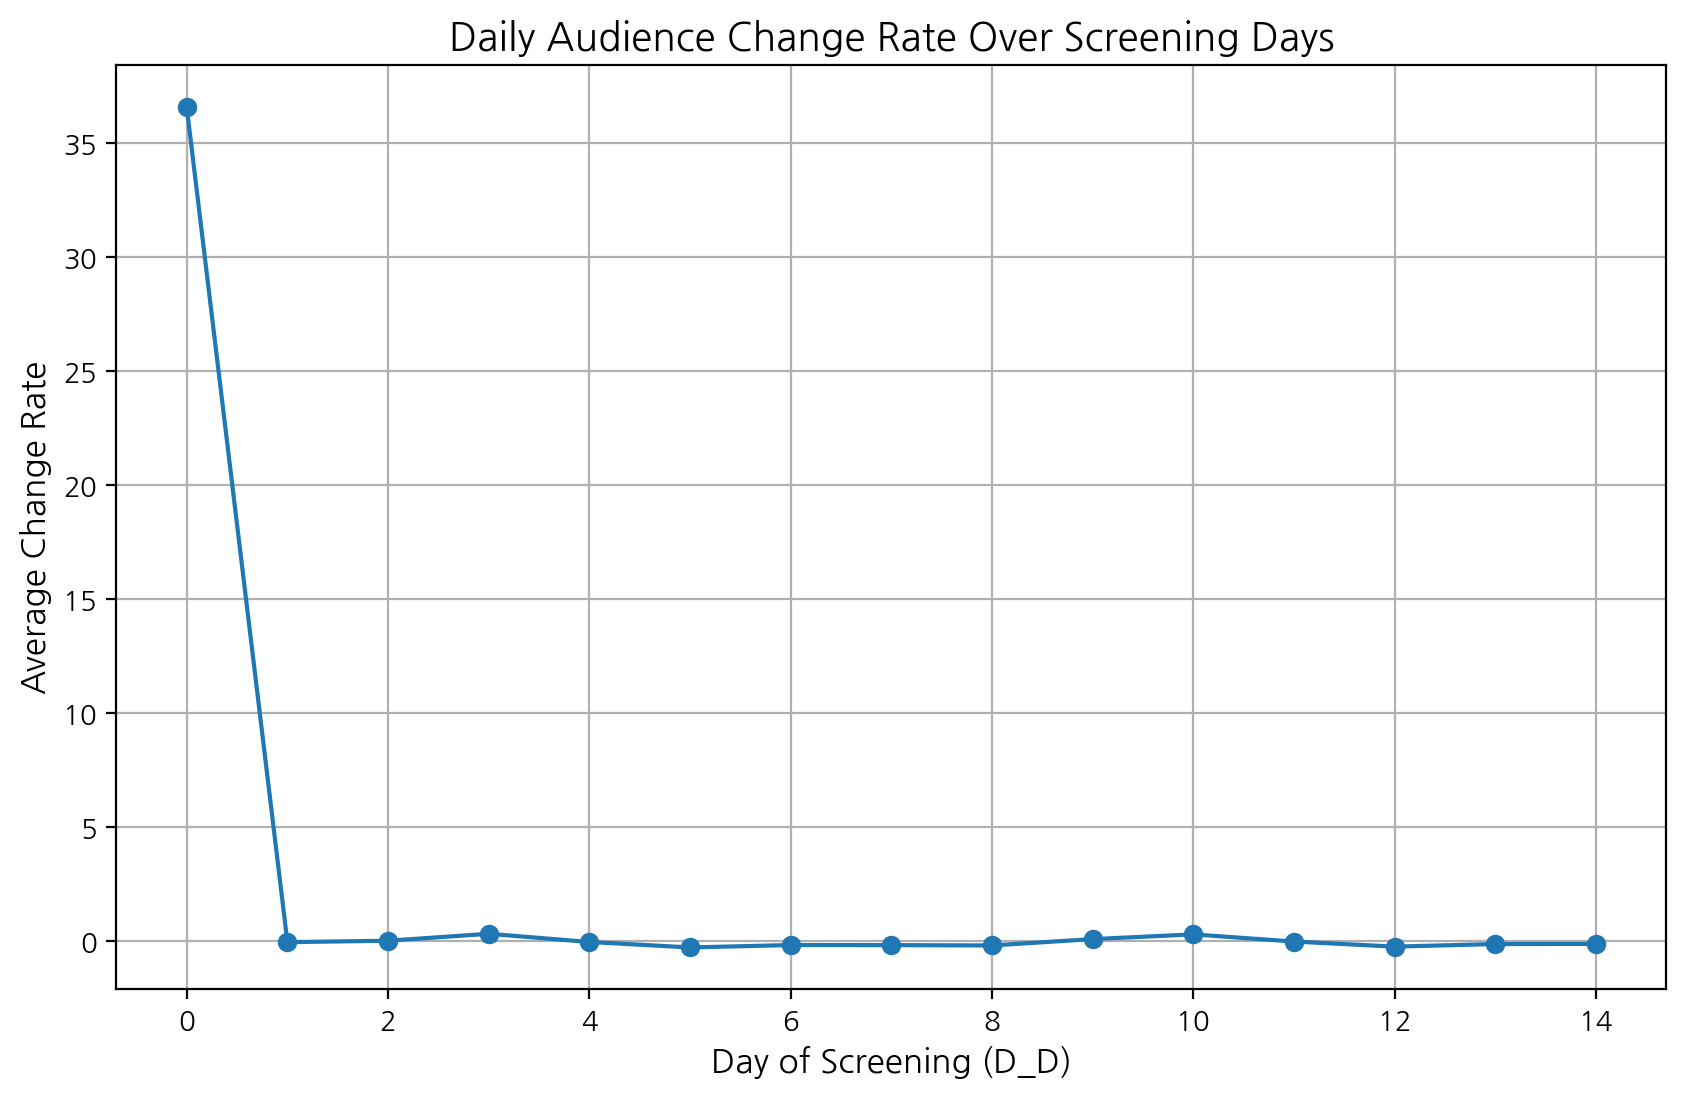

In [5]:
# 상영일 차이에 따른 관객 감소율 시각화
plt.figure(figsize=(10, 6))
plt.plot(daily_change_summary['D_D'], daily_change_summary['DailyTotal_change_rate'], marker='o', linestyle='-')
plt.title('Daily Audience Change Rate Over Screening Days', fontsize=14)
plt.xlabel('Day of Screening (D_D)', fontsize=12)
plt.ylabel('Average Change Rate', fontsize=12)
plt.grid(True)
plt.show()

In [6]:
# 변수명과 데이터 타입 정리
variables_summary = pd.DataFrame({
    'Column Name': df.columns,
    'Data Type': df.dtypes.astype(str)
})

# 변수 목록 확인
print(variables_summary)

                                   Column Name Data Type
naver_movie_code              naver_movie_code     int64
kobis_movie_code              kobis_movie_code     int64
movie_title                        movie_title    object
release_date                      release_date    object
DoW_release                        DoW_release    object
...                                        ...       ...
5days_before                      5days_before     int64
Day_of_release                  Day_of_release     int64
5days_after                        5days_after     int64
7days_after                        7days_after     int64
DailyTotal_change_rate  DailyTotal_change_rate   float64

[173 rows x 2 columns]


### 1. 매출/관객 수 관련 기준
이 기준에서는 영화의 흥행 성과를 기반으로 클러스터링을 진행합니다.

매출액, 관객수, 누적매출액, 누적관객수 등을 기준으로 클러스터링할 수 있습니다.

준비 단계
* 먼저, 매출액과 관객수 관련 데이터를 선택합니다.
* 결측값이 있으면 제거하거나 적절히 처리합니다.
* 스케일링을 진행하여 데이터의 차이를 조정합니다.

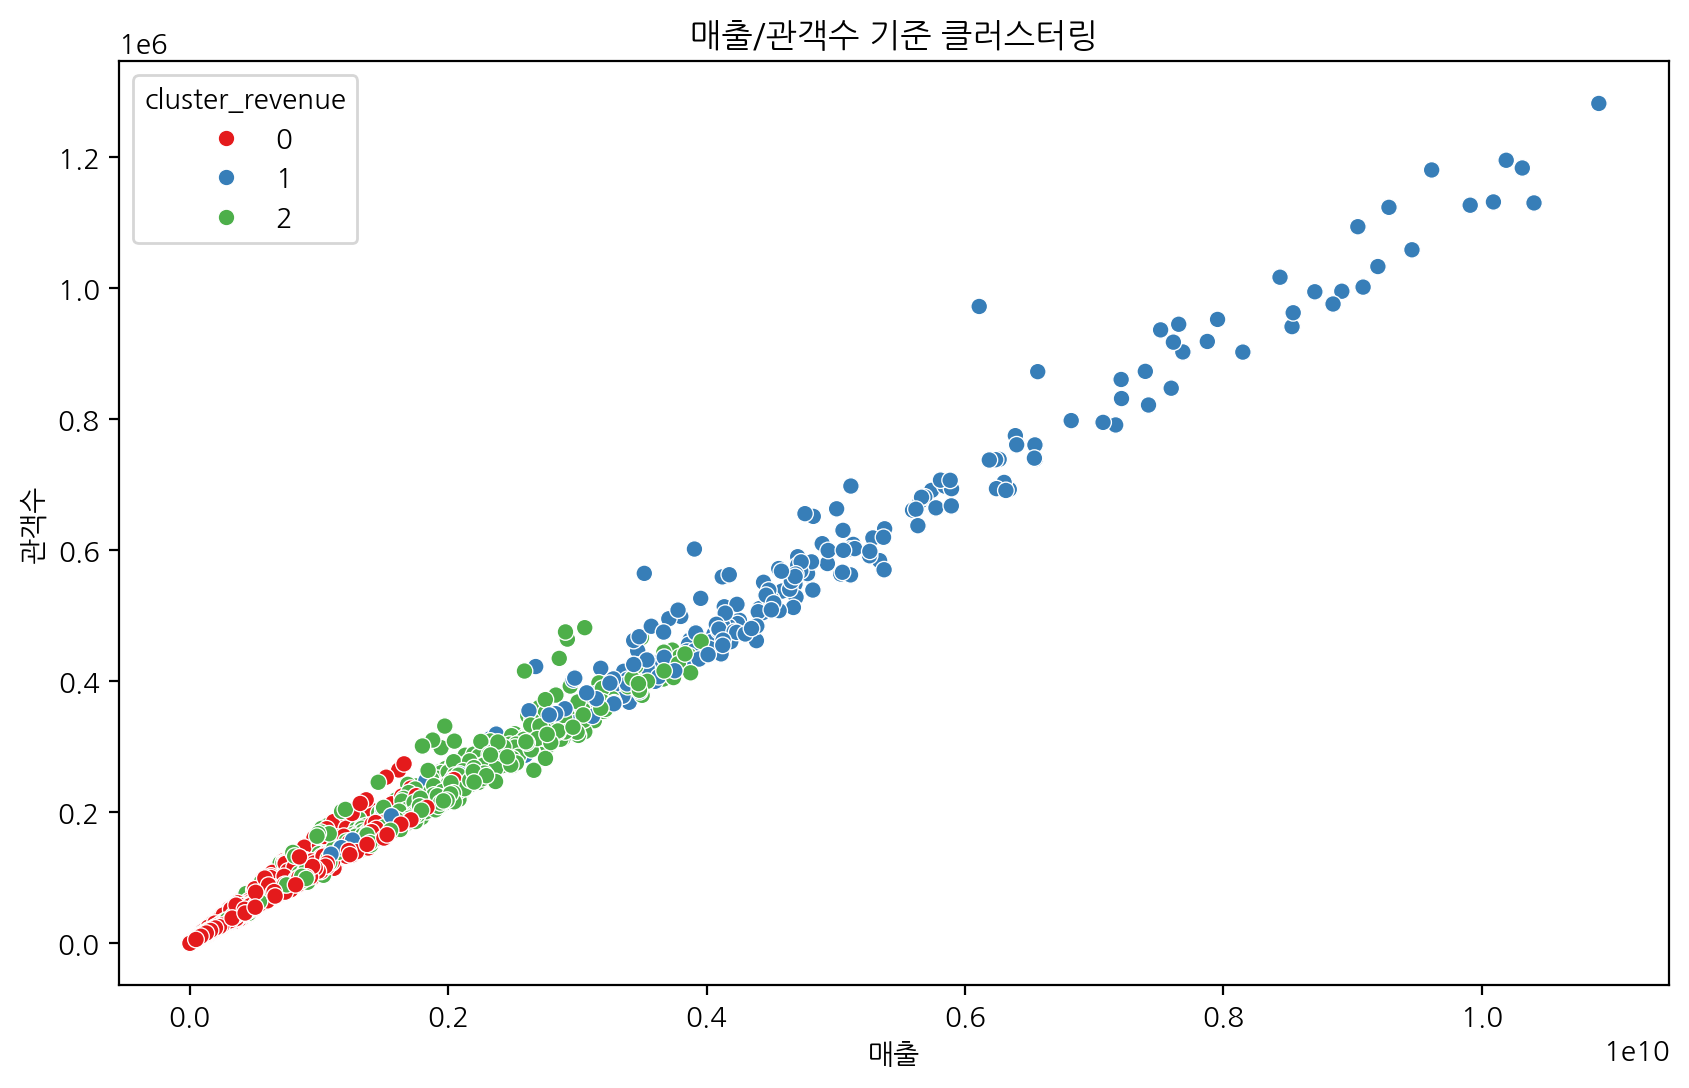

In [7]:
# 필요한 열 선택
df_revenue = df[['매출액', '관객수', '누적매출액', '누적관객수']]

# 결측값 제거
df_revenue = df_revenue.dropna()

# 데이터 스케일링 (Min-Max 스케일링) -> K-Means는 거리 기반 알고리즘으로, 변수의 단위 차이가 클 경우 특정 변수에 의해 결과가 왜곡될 수 있음
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
df_scaled = scaler.fit_transform(df_revenue)

# K-Means 클러스터링
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=3, random_state=42)  # 클러스터 수는 3으로 설정
df['cluster_revenue'] = kmeans.fit_predict(df_scaled)

# 결과 확인
plt.figure(figsize=(10, 6))
sns.scatterplot(x=df['매출액'], y=df['관객수'], hue=df['cluster_revenue'], palette='Set1')
plt.title('매출/관객수 기준 클러스터링')
plt.xlabel('매출')
plt.ylabel('관객수')
plt.show()

In [12]:
# 클러스터별 특성 분석
df['cluster_revenue'] = kmeans.predict(df_scaled)

# 각 클러스터별 평균값 계산
cluster_means = df.groupby('cluster_revenue')[['매출액', '관객수', '누적매출액', '누적관객수']].mean()
cluster_means

클러스터링 결과를 보면, 각 클러스터의 특성은 다음과 같습니다:

1. **클러스터 0**:
   - **매출액**: 약 276억 원
   - **관객수**: 약 34,605명
   - **누적매출액**: 약 2,837억 원
   - **누적관객수**: 약 35만 명
   
   클러스터 0은 상대적으로 **낮은 매출과 관객수**를 기록한 영화들이 포함된 그룹으로 볼 수 있습니다.

2. **클러스터 1**:
   - **매출액**: 약 45억 원
   - **관객수**: 약 533,889명
   - **누적매출액**: 약 2,929억 원
   - **누적관객수**: 약 355만 명
   
   클러스터 1은 **매출과 관객수가 매우 높은** 영화들이 포함된 그룹으로, 성공적인 영화들이 대부분 분포하고 있습니다.

3. **클러스터 2**:
   - **매출액**: 약 133억 원
   - **관객수**: 약 162,069명
   - **누적매출액**: 약 1,586억 원
   - **누적관객수**: 약 191만 명
   
   클러스터 2는 **중간 정도의 매출과 관객수**를 기록한 영화들로, 클러스터 1보다 성과는 낮지만 클러스터 0보다는 더 높은 성과를 보인 영화들이 모여 있는 그룹입니다.

### 해석:
- **클러스터 0**은 매출과 관객수가 낮은 영화들이 주로 모여 있으며, 이러한 영화들은 상대적으로 낮은 수익을 기록한 작품들일 가능성이 높습니다.
- **클러스터 1**은 가장 높은 매출액과 관객수를 기록한 영화들이 포함되어 있습니다. 이는 흥행 성과가 뛰어난 영화들이 이 그룹에 속하는 것으로 볼 수 있습니다.
- **클러스터 2**는 중간 수준의 성과를 보인 영화들이 모여 있는 클러스터입니다.

이러한 분류를 통해 각 클러스터에 속하는 영화들의 특성을 바탕으로, 마케팅 전략이나 영화 선정에 참고할 수 있는 인사이트를 도출할 수 있습니다. 예를 들어, 클러스터 1에 속하는 영화들은 대규모 마케팅 및 배급을 통해 높은 수익을 올린 경우가 많기 때문에, 이들과 비슷한 특성을 가진 영화들을 타겟팅하는 전략을 구상할 수 있습니다.

In [9]:
# 각 클러스터에 속하는 영화 제목들을 확인
cluster_movies = df.groupby('cluster_revenue')['movie_title'].apply(list)

# 결과 출력
print(cluster_movies)

cluster_revenue
0    [나를 잊지 말아요, 나를 잊지 말아요, 나를 잊지 말아요, 나를 잊지 말아요, 나...
1    [쿵푸팬더3, 쿵푸팬더3, 검사외전, 검사외전, 검사외전, 검사외전, 검사외전, 검...
2    [레버넌트: 죽음에서 돌아온 자, 레버넌트: 죽음에서 돌아온 자, 레버넌트: 죽음에...
Name: movie_title, dtype: object


In [63]:
# cluster1_movies.csv로 저장
df.to_csv('cluster1_movies.csv', index=False, encoding='utf-8-sig')

#### 2. 영화 장르 기준
영화 장르는 다양한 특성에 따라 영화를 구분할 수 있는 좋은 기준입니다. 

장르 변수는 여러 개의 장르가 있을 수 있으므로, 더미 변수를 만들어서 클러스터링에 사용할 수 있습니다.

준비 단계
* 장르 변수를 다중 더미 변수로 변환합니다.
* pandas.get_dummies()를 사용하여 장르를 분리합니다.

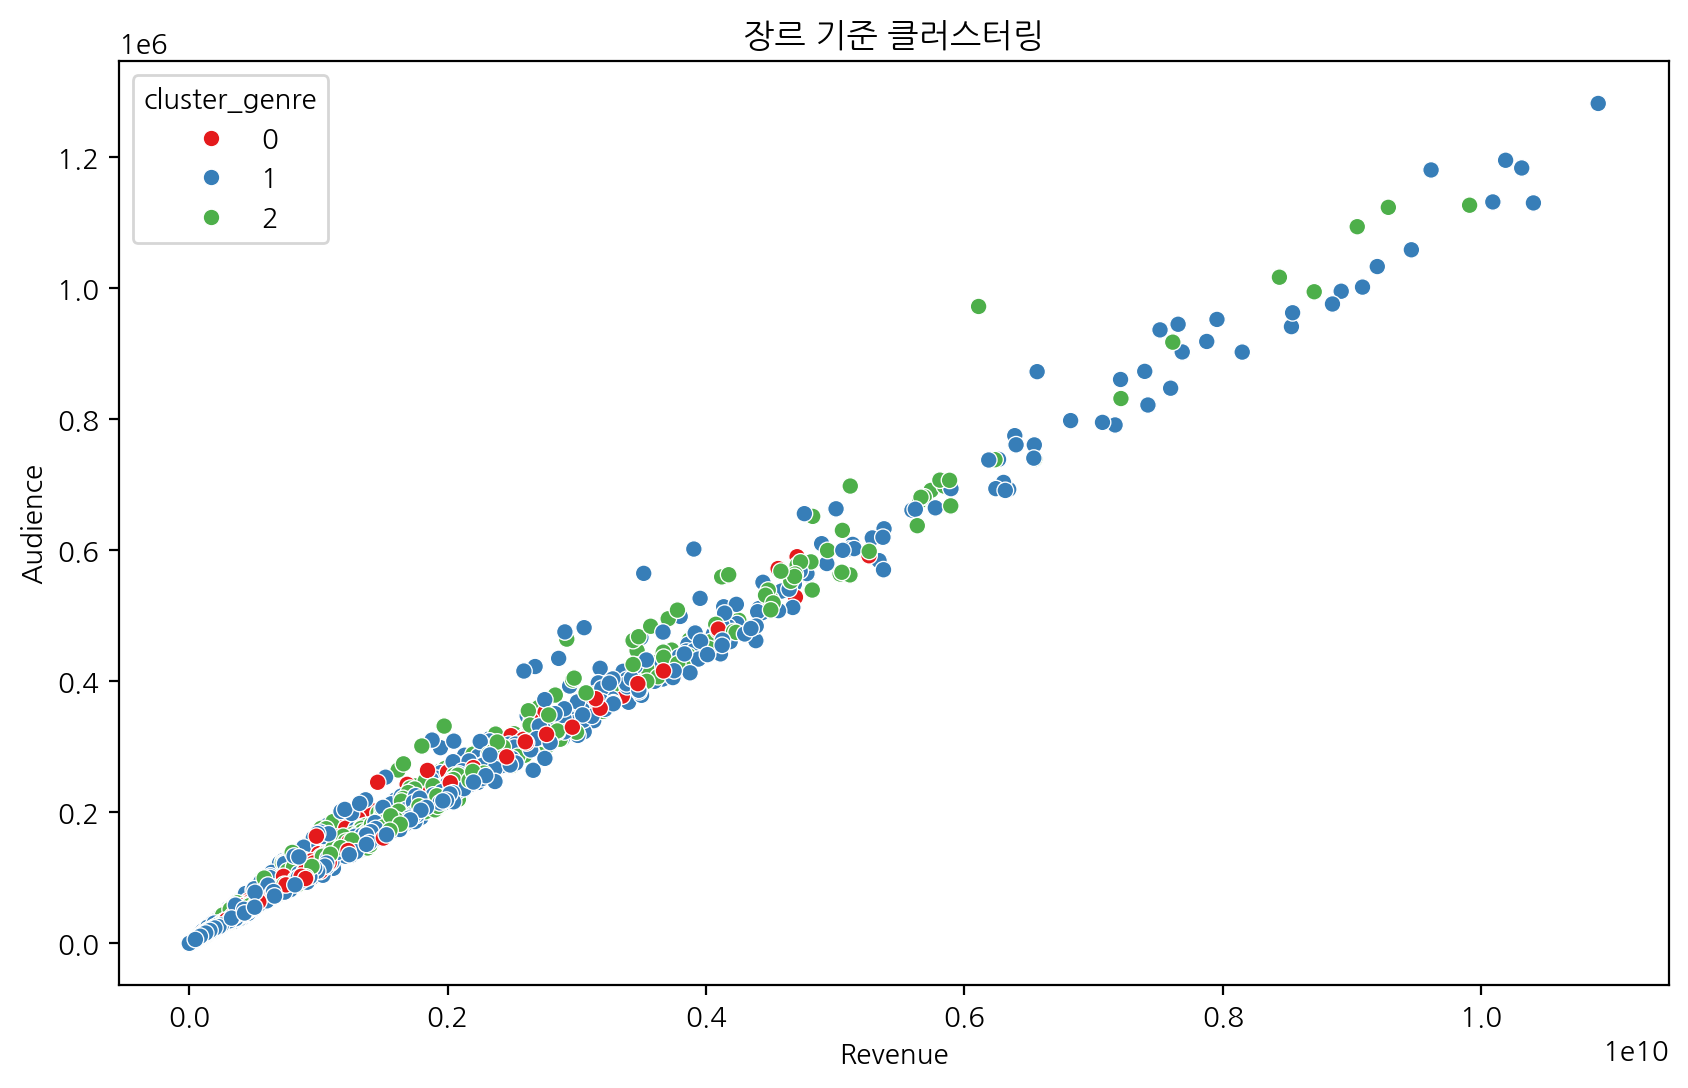

In [10]:
# 장르 더미 변수 생성
df_genres = df['genre'].str.get_dummies(sep=',')  # 여러 장르가 있을 수 있어 쉼표로 구분하여 나눔

# K-Means 클러스터링
df_scaled_genres = scaler.fit_transform(df_genres)  # 장르 데이터도 스케일링
kmeans_genres = KMeans(n_clusters=3, random_state=42)
df['cluster_genre'] = kmeans_genres.fit_predict(df_scaled_genres)

# 결과 확인
plt.figure(figsize=(10, 6))
sns.scatterplot(x=df['매출액'], y=df['관객수'], hue=df['cluster_genre'], palette='Set1')
plt.title('장르 기준 클러스터링')
plt.xlabel('Revenue')
plt.ylabel('Audience')
plt.show()

In [11]:
# 클러스터별 주요 장르 분포 확인
genre_columns = df_genres.columns  # 장르 더미 변수 컬럼
cluster_genre_distribution = df.groupby('cluster_genre')[genre_columns].mean()

cluster_genre_distribution

### 클러스터별 장르 특성 해석

위의 결과는 각 클러스터에서 특정 장르가 차지하는 평균 비율을 보여줍니다. 각 클러스터별 주요 장르 특성을 분석해 보겠습니다.

---

#### **1. 클러스터 0**
- **주요 장르**:
  - **애니메이션**: 94.20% (가장 큰 비중)
  - **어드벤처**: 40.58%
  - **코미디**: 21.73%
  - **가족**: 21.73%
- **특징**:
  - **애니메이션 중심**의 영화가 대부분.
  - 가족과 함께 즐길 수 있는 어드벤처, 코미디 장르 영화가 많이 포함됨.
  - 일반적으로 **가족 친화적인 영화**로 구성된 클러스터로 보입니다.

---

#### **2. 클러스터 1**
- **주요 장르**:
  - **액션**: 51.71% (가장 큰 비중)
  - **스릴러**: 25.85%
  - **어드벤처**: 21.95%
  - **범죄**: 14.15%
  - **공포(호러)**: 11.22%
- **특징**:
  - **액션 중심**의 영화가 가장 많으며, 스릴러, 범죄 장르도 높은 비중.
  - 공포 영화가 포함되어 있어 **성인 관객층**이 주요 타겟인 클러스터로 보입니다.
  - 긴장감과 몰입감을 주는 영화가 주를 이루는 경향.

---

#### **3. 클러스터 2**
- **주요 장르**:
  - **드라마**: 99.26% (압도적 비중)
  - **멜로/로맨스**: 9.63%
  - **액션**: 9.63%
  - **스릴러**: 8.88%
  - **범죄**: 8.88%
- **특징**:
  - 거의 모든 영화가 **드라마 장르**에 속함.
  - 멜로/로맨스, 범죄, 스릴러 등 다양한 하위 장르를 포함.
  - 감정과 이야기에 중점을 둔 **스토리 중심 영화** 클러스터.

---

### **요약**
1. **클러스터 0**:
   - **가족 친화적인 영화** (애니메이션, 코미디, 어드벤처).
   - 어린이와 가족 관객 타겟.

2. **클러스터 1**:
   - **성인 관객 중심의 액션, 스릴러, 범죄 영화**.
   - 긴장감과 몰입감 높은 영화.

3. **클러스터 2**:
   - **감성적인 드라마 중심의 영화**.
   - 스토리와 감정이 중요한 작품들.

---

이 분석 결과를 바탕으로 각 클러스터를 타겟팅한 마케팅 전략을 수립할 수 있습니다. 예를 들어:
- **클러스터 0**: 가족 관객을 대상으로 광고 및 캠페인.
- **클러스터 1**: 성인 남성 관객 타겟팅.
- **클러스터 2**: 감성적인 이야기를 선호하는 관객층 타겟.

<Figure size 1000x600 with 0 Axes>

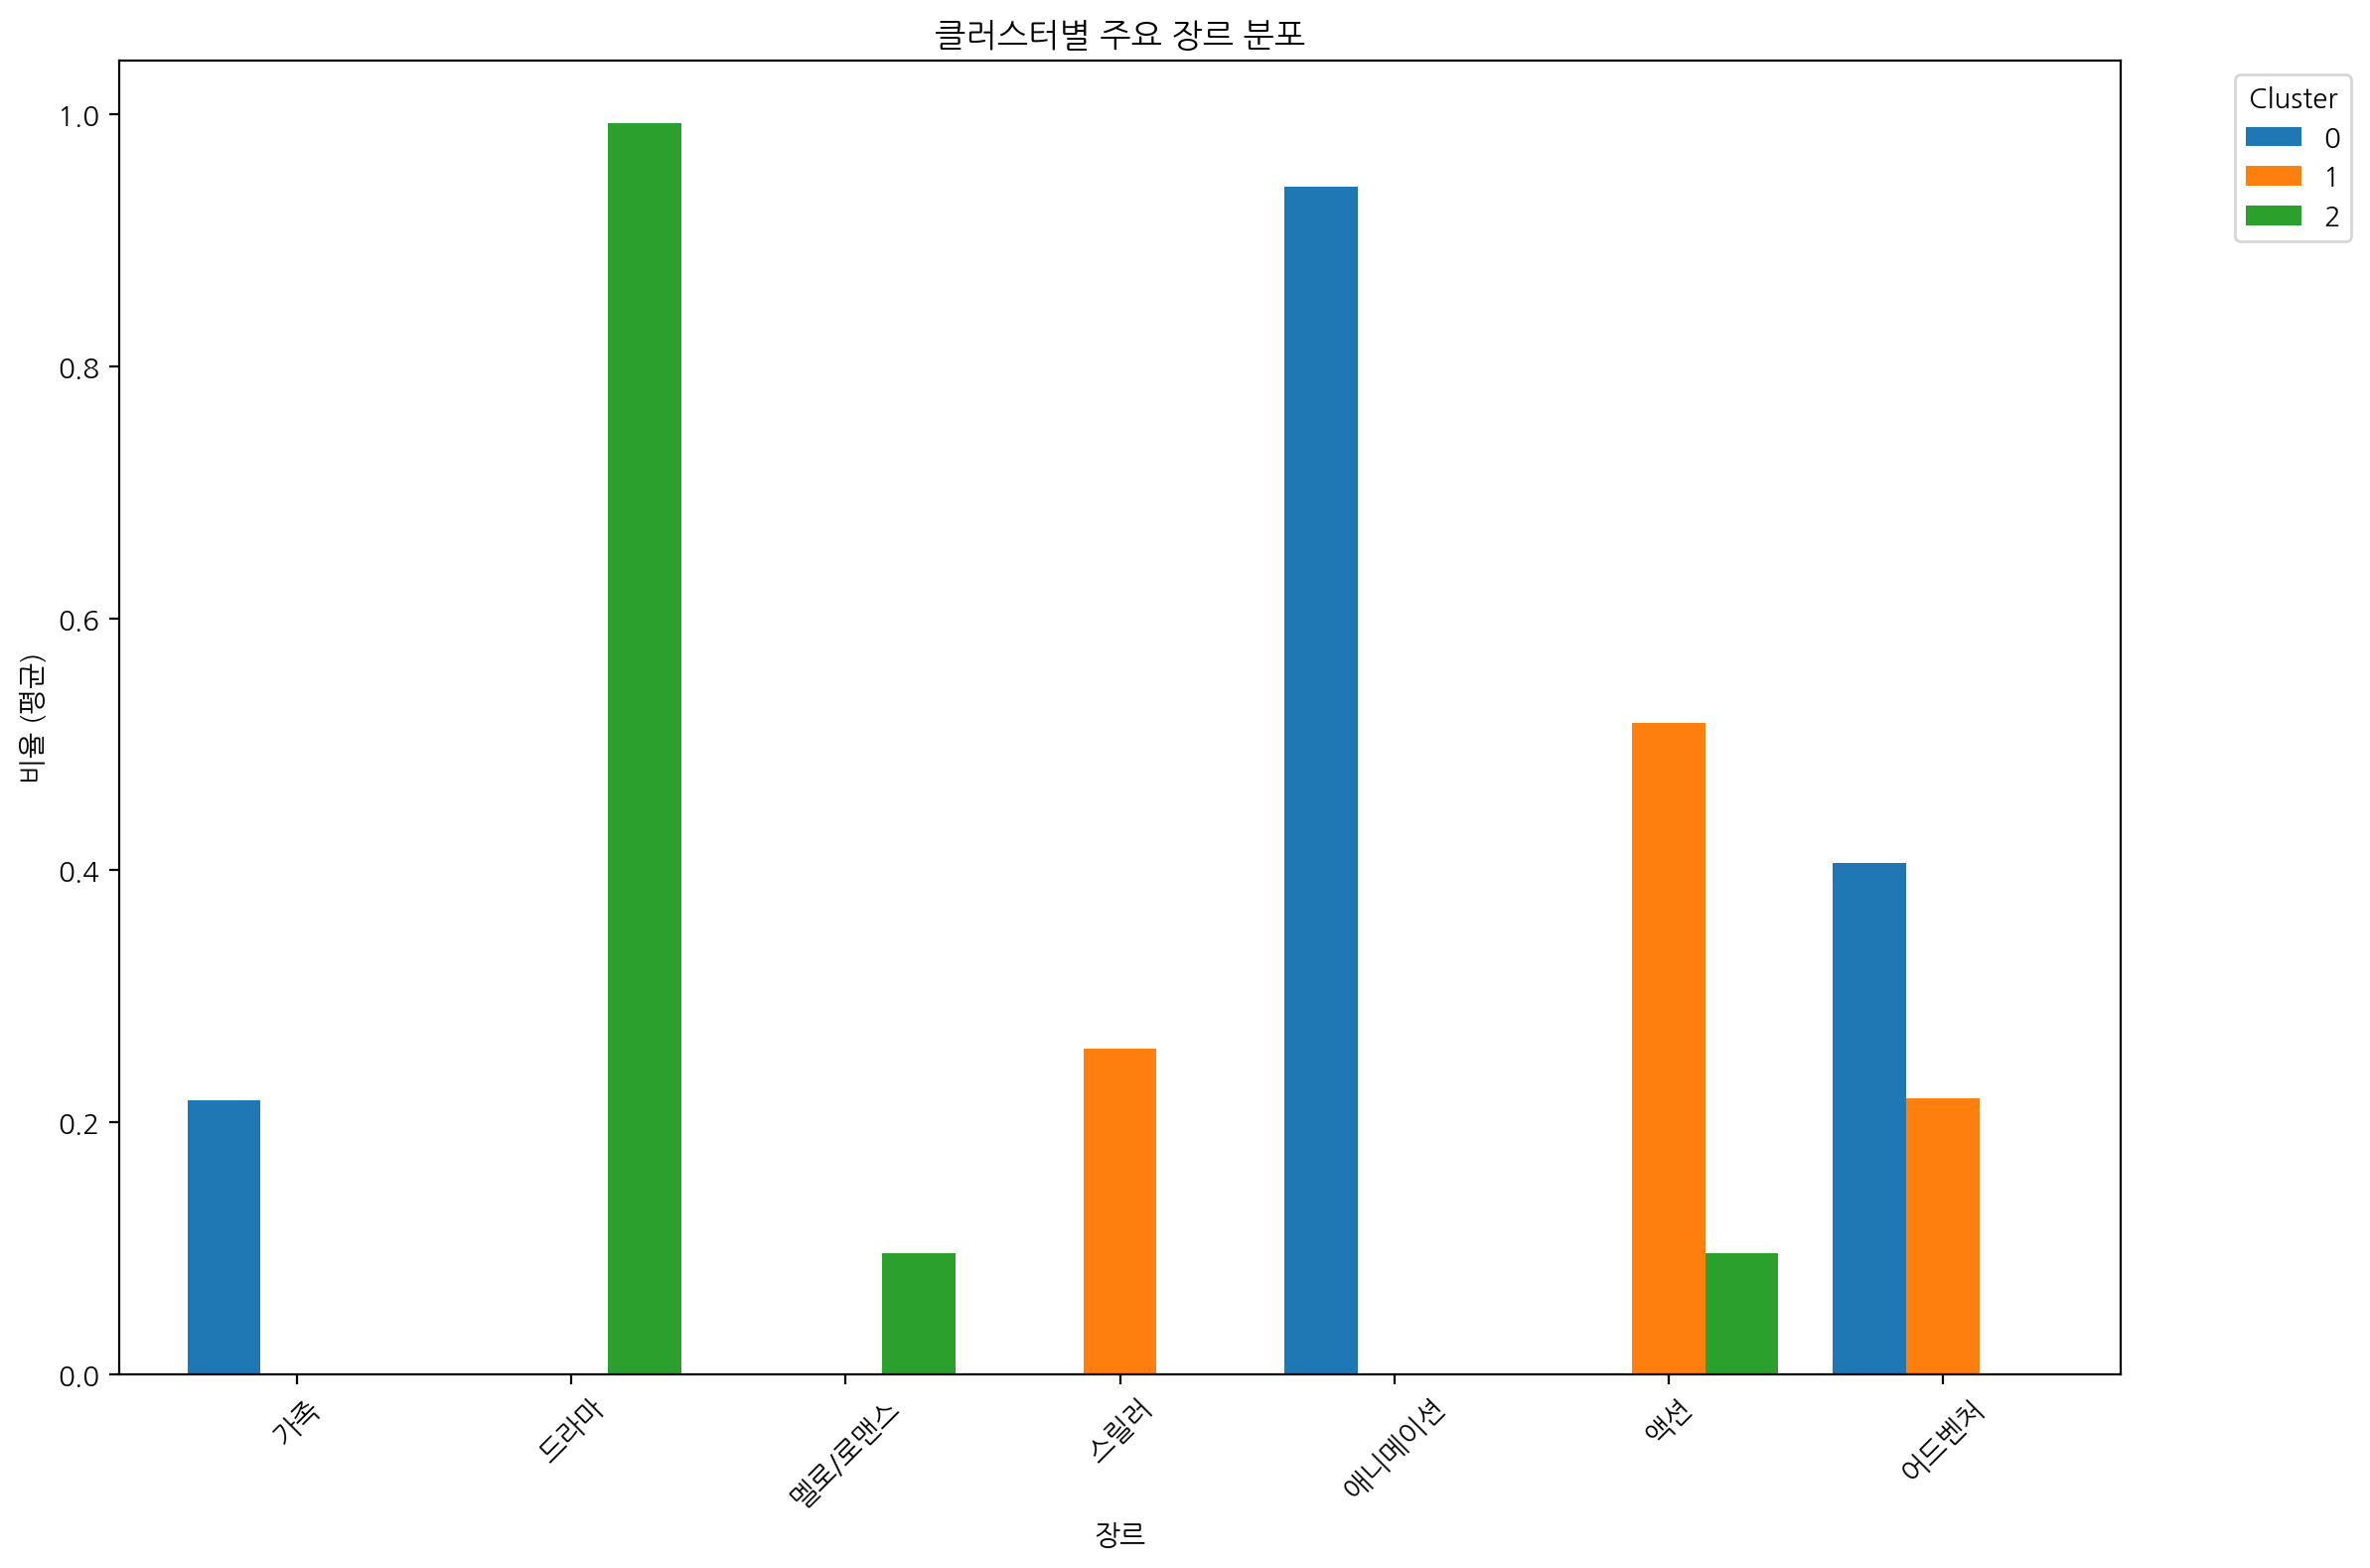

In [13]:
# 상위 3개 장르를 시각화하여 확인
top_genres = cluster_genre_distribution.apply(lambda x: x.nlargest(3), axis=1)

# 클러스터별 상위 장르 시각화
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
top_genres.T.plot(kind='bar', figsize=(12, 8), width=0.8)
plt.title("클러스터별 주요 장르 분포")
plt.ylabel("비율 (평균)")
plt.xlabel("장르")
plt.xticks(rotation=45)
plt.legend(title="Cluster", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

#### 3. 상영 관련 기준
이 기준에서는 스크린수, 상영횟수, 좌석수 등을 사용하여 상영 빈도와 상영 규모를 기준으로 클러스터링을 할 수 있습니다.

준비 단계
* 관련된 변수들을 선택하고 결측값을 처리한 후, 클러스터링을 진행합니다.

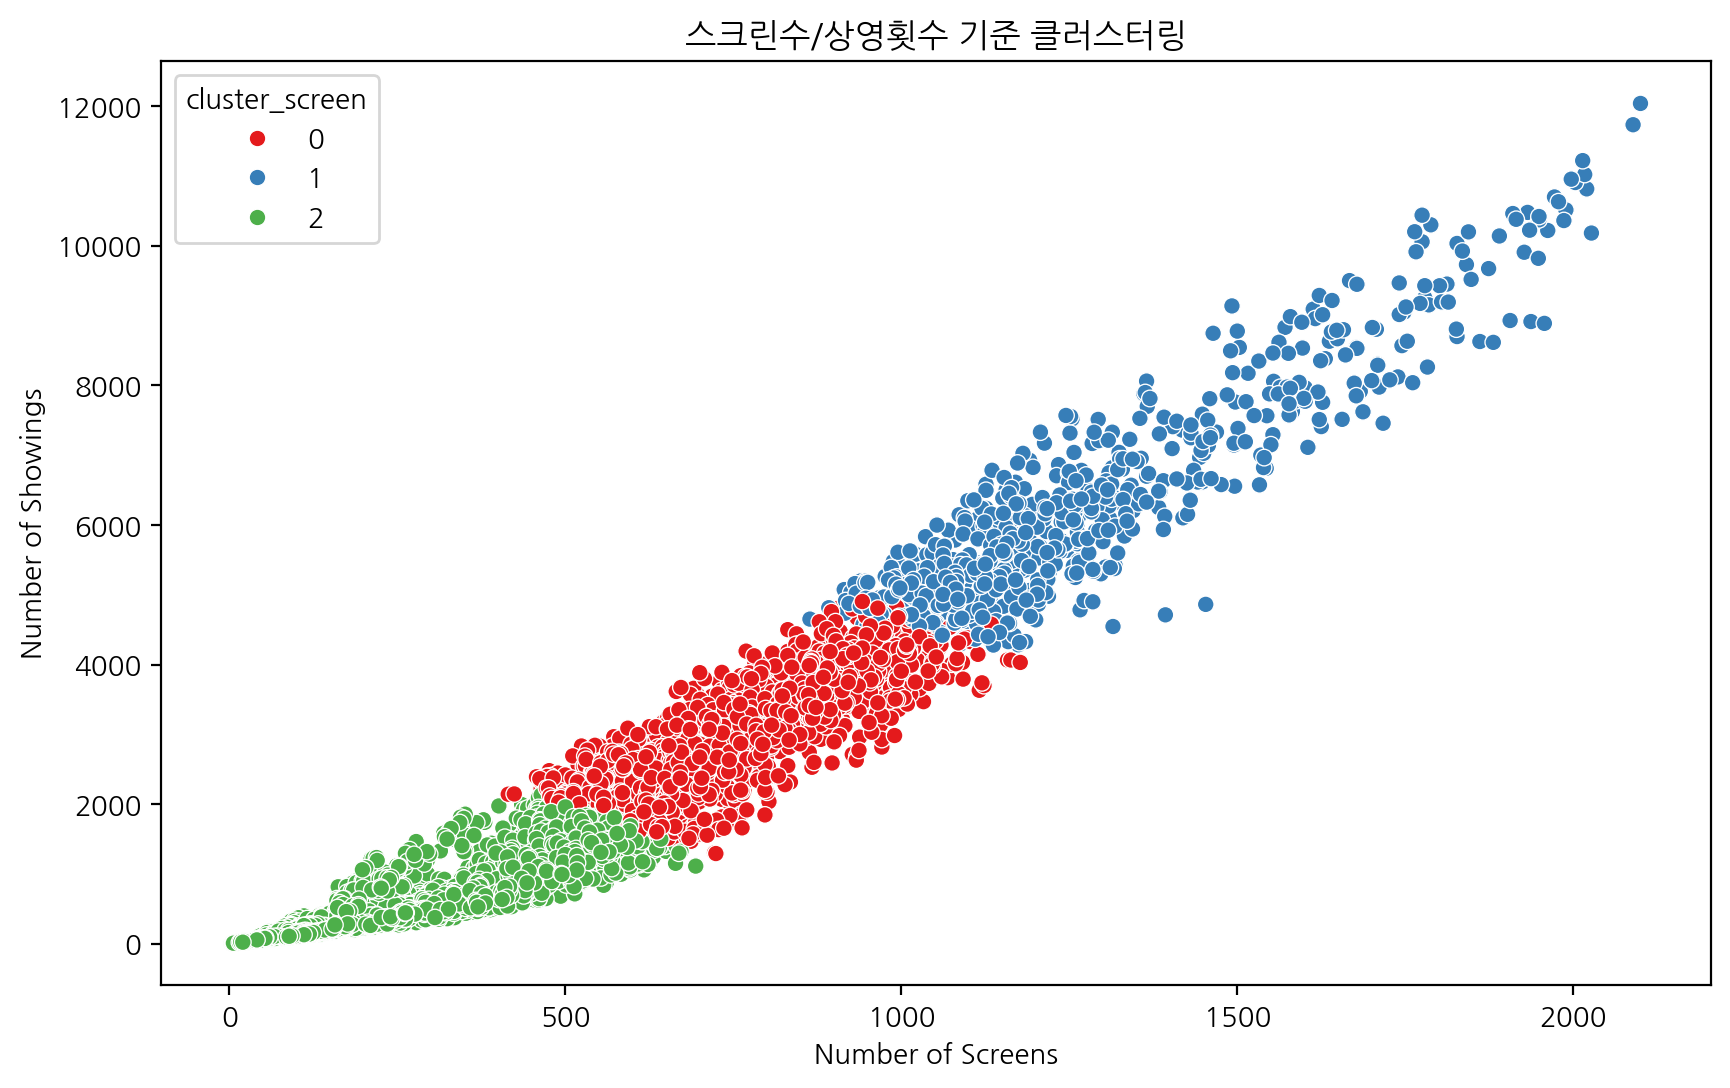

In [15]:
# 상영 관련 변수 선택
df_screen = df[['스크린수', '상영횟수', '좌석수']]

# 결측값 제거
df_screen = df_screen.dropna()

# 데이터 스케일링
df_scaled_screen = scaler.fit_transform(df_screen)

# K-Means 클러스터링
kmeans_screen = KMeans(n_clusters=3, random_state=42)
df['cluster_screen'] = kmeans_screen.fit_predict(df_scaled_screen)

# 결과 확인
plt.figure(figsize=(10, 6))
sns.scatterplot(x=df['스크린수'], y=df['상영횟수'], hue=df['cluster_screen'], palette='Set1')
plt.title('스크린수/상영횟수 기준 클러스터링')
plt.xlabel('Number of Screens')
plt.ylabel('Number of Showings')
plt.show()

In [16]:
# 클러스터별 평균값 계산
cluster_screen_summary = df.groupby('cluster_screen')[['스크린수', '상영횟수', '좌석수']].mean()

# 결과 출력
cluster_screen_summary

### **스크린/상영/좌석 기준 클러스터링 결과 해석**

#### **클러스터별 분석**
| **클러스터** | **스크린수** | **상영횟수** | **좌석수**          | **특징**                                       |
|--------------|--------------|--------------|---------------------|------------------------------------------------|
| **클러스터 0** | 734.68       | 2959.32      | 492,061             | 중대형 규모 상영: 대형 배급사 상업 영화, 주요 상영관에서 지속 상영. |
| **클러스터 1** | 1261.51      | 6189.65      | 1,151,090           | 초대형 상영: 블록버스터 영화, 대규모 관객 타겟. |
| **클러스터 2** | 301.61       | 701.46       | 97,196              | 소규모 상영: 독립영화나 제한적 개봉 영화, 관객 타겟이 제한적. |

---

### **각 클러스터의 해석**

1. **클러스터 0 (중대형 규모 상영)**:
   - 평균 **스크린 수**: 734개  
   - 평균 **상영 횟수**: 2959회  
   - 평균 **좌석 수**: 약 49만석  
   - **특징**:
     - 중대형 상업 영화.
     - 상영관 수는 많지만 블록버스터보다는 약간 낮은 규모.
     - 대중성을 가진 영화들이 속할 가능성이 큼.

2. **클러스터 1 (초대형 상영)**:
   - 평균 **스크린 수**: 1261개  
   - 평균 **상영 횟수**: 6189회  
   - 평균 **좌석 수**: 약 115만석  
   - **특징**:
     - 블록버스터 영화가 주로 속함.
     - 개봉 첫 주에 상영 스크린과 횟수가 극대화됨.
     - 대형 영화제작사와 협력한 영화.

3. **클러스터 2 (소규모 상영)**:
   - 평균 **스크린 수**: 301개  
   - 평균 **상영 횟수**: 701회  
   - 평균 **좌석 수**: 약 9.7만석  
   - **특징**:
     - 독립영화 또는 예술 영화.
     - 특정 지역이나 소수 관객을 대상으로 상영.
     - 흥행을 목표로 하지 않고, 특정 관객층에 집중.

---

### **시각적 해석**
- **클러스터 0**: 중간 정도의 스크린 수와 상영 횟수를 가진 점들이며, **대중성 있는 상업 영화**.
- **클러스터 1**: 스크린 수와 상영 횟수가 가장 많은 점들로, **블록버스터**를 나타냄.
- **클러스터 2**: 스크린 수와 상영 횟수가 가장 적은 점들로, **독립/소규모 영화**.

#### 4. 영화 평점 및 댓글 기준
영화의 평점, 댓글 수, 긍정/부정/중립 댓글 비율 등을 기준으로 클러스터링을 진행할 수 있습니다.

준비 단계
* 평점과 댓글 수, 그리고 댓글 비율 관련 데이터를 선택합니다.
* 결측값을 처리하고 클러스터링을 진행합니다.

/var/folders/7j/q4f5lfds7cn41ftj48m1vkn40000gn/T/ipykernel_40420/2013540547.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_ratings_cleaned['cluster_ratings'] = kmeans_ratings.fit_predict(df_scaled_ratings)


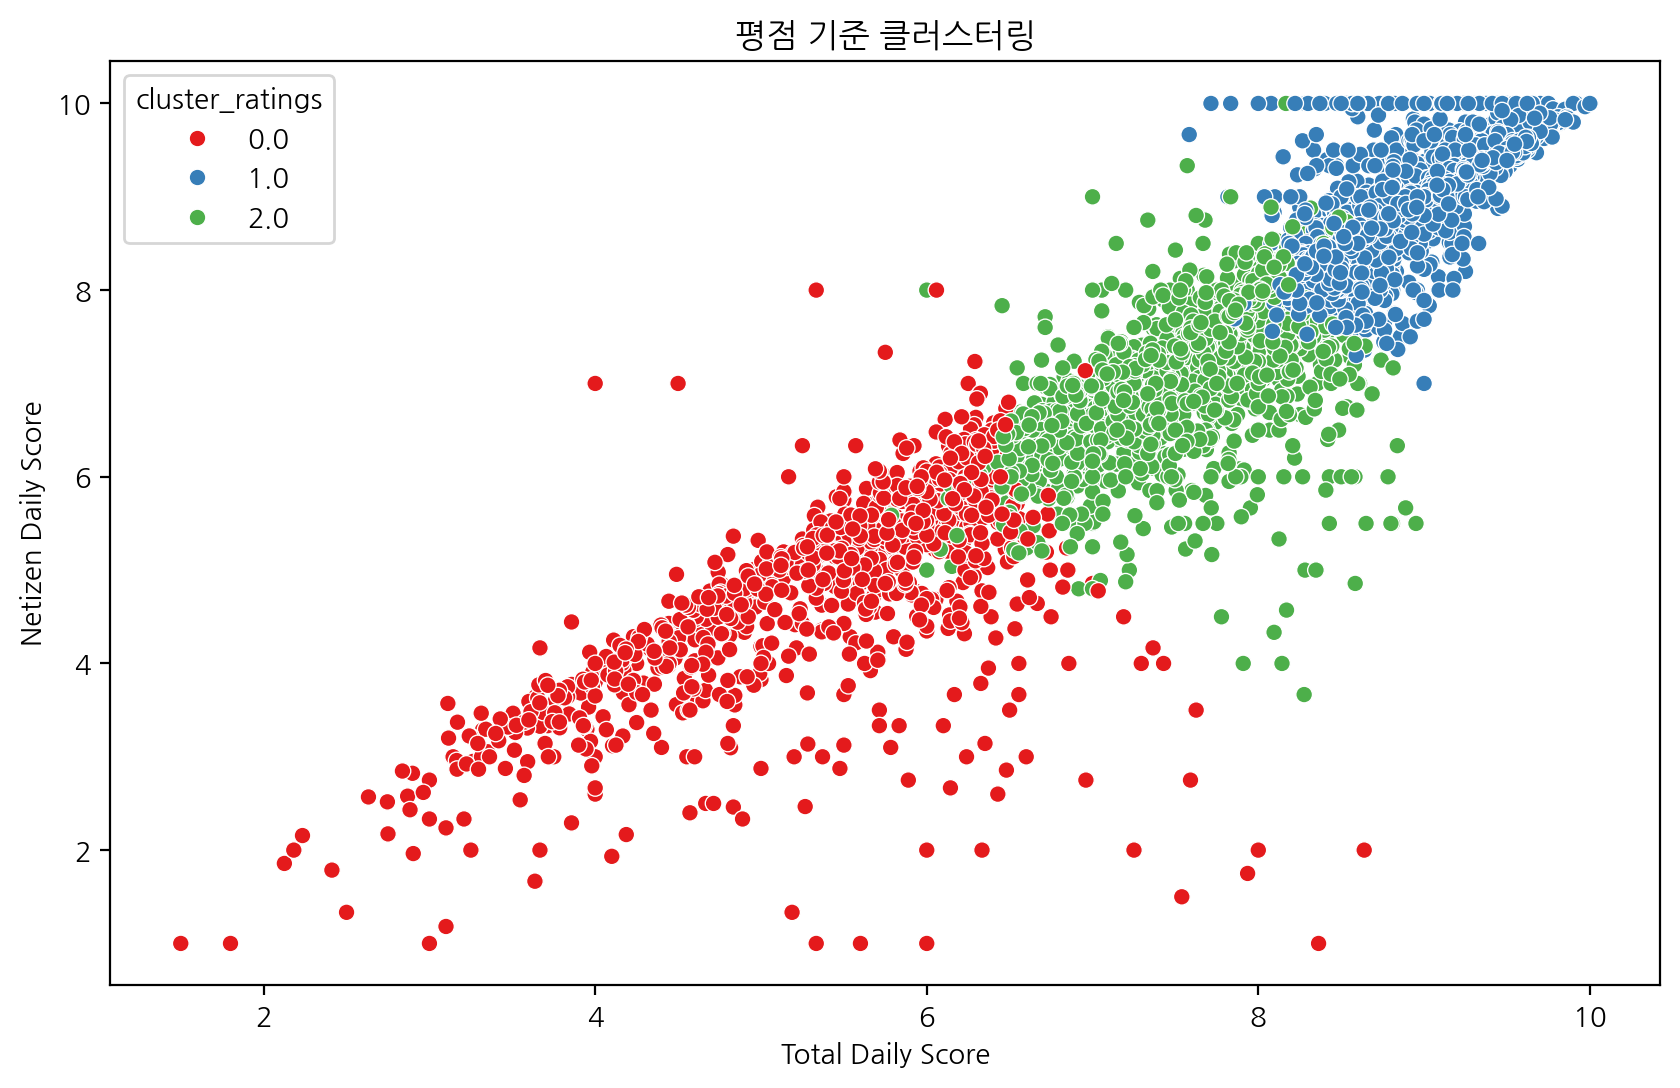

In [18]:
# 결측값 처리: 클러스터링에 사용할 열에서 결측값이 있는 행 제거
df_ratings = df[['Total_Dailyscore', 'RV_Dailyscore', 'NTZ_Dailyscore', 'Total_Negative', 'Total_Positive']]
df_ratings_cleaned = df_ratings.dropna()

# 데이터 스케일링
scaler = MinMaxScaler()
df_scaled_ratings = scaler.fit_transform(df_ratings_cleaned)

# K-Means 클러스터링
kmeans_ratings = KMeans(n_clusters=3, random_state=42)
df_ratings_cleaned['cluster_ratings'] = kmeans_ratings.fit_predict(df_scaled_ratings)

# 원본 데이터에 클러스터 결과 반영
df['cluster_ratings'] = np.nan  # 먼저 원본 데이터
df.loc[df_ratings_cleaned.index, 'cluster_ratings'] = df_ratings_cleaned['cluster_ratings']

# 결과 확인 (매출액과 관객수로 시각화)
plt.figure(figsize=(10, 6))
sns.scatterplot(x=df['Total_Dailyscore'], y=df['NTZ_Dailyscore'], hue=df['cluster_ratings'], palette='Set1')
plt.title('평점 기준 클러스터링')
plt.xlabel('Total Daily Score')
plt.ylabel('Netizen Daily Score')
plt.show()

In [19]:
# 클러스터별 주요 변수의 평균값 계산
cluster_ratings_summary = df.groupby('cluster_ratings')[['Total_Dailyscore', 'RV_Dailyscore', 'NTZ_Dailyscore', 'Total_Negative', 'Total_Positive']].mean()

# 결과 출력
cluster_ratings_summary

### 클러스터별 평점 특성 분석

#### 1. **클러스터 0**
- **평균 평점 (Total_Dailyscore)**: 5.37로 전체에서 가장 낮은 수준입니다.
- **실관람객 평점 (RV_Dailyscore)**: 6.35로 다소 긍정적이나, 네티즌 평점보다 높습니다.
- **네티즌 평점 (NTZ_Dailyscore)**: 4.78로 실관람객보다 더 낮고, 비교적 부정적인 평가가 많음을 보여줍니다.
- **부정적 댓글 수 (Total_Negative)**: 평균 80.53개로, 부정적인 의견이 적지 않습니다.
- **긍정적 댓글 수 (Total_Positive)**: 평균 149.00개로, 긍정적 의견이 부정적 의견을 압도합니다.

> **특징 요약**: 
> - 전체적으로 평점이 낮고, 네티즌 평점이 가장 낮습니다.
> - 부정적인 댓글이 많지만 긍정적 댓글이 더 많아 관객 간 의견이 엇갈리는 영화들로 구성될 가능성이 높습니다.

---

#### 2. **클러스터 1**
- **평균 평점 (Total_Dailyscore)**: 8.85로 가장 높은 클러스터입니다.
- **실관람객 평점 (RV_Dailyscore)**: 8.90로 매우 긍정적입니다.
- **네티즌 평점 (NTZ_Dailyscore)**: 8.82로 실관람객과 거의 동일한 수준입니다.
- **부정적 댓글 수 (Total_Negative)**: 평균 68.06개로 가장 적습니다.
- **긍정적 댓글 수 (Total_Positive)**: 평균 211.57개로 모든 클러스터 중 가장 많습니다.

> **특징 요약**:
> - 관객과 네티즌 모두가 긍정적으로 평가한 영화들입니다.
> - 댓글 수로 볼 때 인기 있는 영화가 포함될 가능성이 높습니다.

---

#### 3. **클러스터 2**
- **평균 평점 (Total_Dailyscore)**: 7.59로 중간 수준입니다.
- **실관람객 평점 (RV_Dailyscore)**: 7.97로 네티즌보다 약간 높습니다.
- **네티즌 평점 (NTZ_Dailyscore)**: 7.21로 전체 평균보다 약간 낮습니다.
- **부정적 댓글 수 (Total_Negative)**: 평균 71.04개로 클러스터 1보다는 많지만 클러스터 0보다는 적습니다.
- **긍정적 댓글 수 (Total_Positive)**: 평균 180.16개로 클러스터 1보다는 적지만 클러스터 0보다는 많습니다.

> **특징 요약**:
> - 긍정적인 평가가 다수를 차지하지만, 클러스터 1보다 평점이나 긍정적 댓글이 적습니다.
> - 평범하거나 약간 긍정적인 반응을 보인 영화들이 포함될 가능성이 큽니다.

---


### 해석
- **클러스터 0**: 평점이 낮고 네티즌 평점이 특히 낮아, 관객 반응이 엇갈리거나 실패한 영화일 가능성이 있습니다.
- **클러스터 1**: 모든 관객층에서 높은 평가를 받은 인기 영화들입니다.
- **클러스터 2**: 긍정적인 반응이 주류를 이루지만, 클러스터 1만큼 압도적이지는 않습니다. 무난하거나 중간 정도의 성공을 거둔 영화들이 포함될 수 있습니다.

#### 5. 영화 개봉 시기 및 경쟁 관계 기준 - 미완
영화의 개봉일과 근접 시기 개봉 영화 수 등을 기준으로 클러스터링을 할 수 있습니다.

준비 단계
* 개봉일, 경쟁 영화 수 등의 데이터를 사용하여 클러스터링을 진행합니다.

In [52]:
print(df.columns)

In [59]:
# 1. MoY 열이 월 이름이면 숫자로 변환 (월 이름을 숫자로 변환)
month_mapping = {
    'January': 1, 'February': 2, 'March': 3, 'April': 4, 'May': 5, 'June': 6,
    'July': 7, 'August': 8, 'September': 9, 'October': 10, 'November': 11, 'December': 12
}
df['MoY'] = df['MoY'].map(month_mapping)

# 2. DoW_release 열을 요일 숫자로 변환 (0=월요일, 1=화요일, ..., 6=일요일)
day_mapping = {
    'Monday': 0, 'Tuesday': 1, 'Wednesday': 2, 'Thursday': 3, 'Friday': 4, 'Saturday': 5, 'Sunday': 6
}
df['DoW_release'] = df['DoW_release'].map(day_mapping)

# 3. '7days_before', '5days_before', '5days_after', '7days_after' 변수를 그대로 사용하여 데이터 선택
df_release = df[['release_date', 'MoY', 'DoW_release', '7days_before', '5days_before', 'Day_of_release', '5days_after', '7days_after']]

# 4. 결측값 처리 (결측값이 있는지 확인하고 결측값을 제거)
print(df_release.isnull().sum())  # 결측값 개수 확인
df_release_cleaned = df_release.dropna()  # 결측값이 있는 행 제거

# 결측값을 대체하고 싶다면, 예를 들어, 각 열의 평균 값으로 대체할 수 있습니다.
# df_release_cleaned = df_release.fillna(df_release.mean())

# 5. 데이터 스케일링
scaler = MinMaxScaler()
df_scaled_release = scaler.fit_transform(df_release_cleaned[['MoY', 'DoW_release', '7days_before', '5days_before', 'Day_of_release', '5days_after', '7days_after']])

# 6. K-Means 클러스터링
kmeans_release = KMeans(n_clusters=3, random_state=42)
df_release_cleaned['cluster_release'] = kmeans_release.fit_predict(df_scaled_release)

# 7. 원본 데이터에 클러스터 결과 반영
df['cluster_release'] = np.nan
df.loc[df_release_cleaned.index, 'cluster_release'] = df_release_cleaned['cluster_release']

# 8. 시각화: 개봉 시기 기준 (MoY, DoW_release)
plt.figure(figsize=(10, 6))
sns.scatterplot(x=df['MoY'], y=df['DoW_release'], hue=df['cluster_release'], palette='Set2')
plt.title('Clustering by Release Date and Competition')
plt.xlabel('Month of Year')
plt.ylabel('Release Day of Week')
plt.show()

# 9. 시각화: 경쟁 관계 기준 (7일 전, 5일 후, 당일)
plt.figure(figsize=(10, 6))
sns.scatterplot(x=df['7days_before'], y=df['5days_after'], hue=df['cluster_release'], palette='Set2')
plt.title('Clustering by Competition')
plt.xlabel('Seven Days Before Release')
plt.ylabel('Five Days After Release')
plt.show()

release_date         0
MoY               6135
DoW_release       6135
7days_before         0
5days_before         0
Day_of_release       0
5days_after          0
7days_after          0
dtype: int64


ValueError: Found array with 0 sample(s) (shape=(0, 7)) while a minimum of 1 is required by MinMaxScaler.

#### 6. 영화 제작 관련 기준 - 미완
감독의 능력, 배급사의 인기 등을 기준으로 클러스터링을 할 수 있습니다.

준비 단계
* 감독과 배급사 관련 데이터를 선택하여 클러스터링을 진행합니다.

In [60]:
# 감독 및 배급사 관련 변수 선택
df_director = df[['directors', '배급사', '감독평균최대관객수', '배급사평균최대관객수']]

# 결측값 제거
df_director = df_director.dropna()

# 데이터 스케일링
df_scaled_director = scaler.fit_transform(df_director)

# K-Means 클러스터링
kmeans_director = KMeans(n_clusters=3, random_state=42)
df['cluster_director'] = kmeans_director.fit_predict(df_scaled_director)

# 결과 확인
plt.figure(figsize=(10, 6))
sns.scatterplot(x=df['감독평균최대관객수'], y=df['배급사평균최대관객수'], hue=df['cluster_director'], palette='Set6')
plt.title('Clustering by Director and Distributor')
plt.xlabel('Director Average Max Audience')
plt.ylabel('Distributor Average Max Audience')
plt.show()

ValueError: could not convert string to float: '이윤정'